# 15. 순수 비지도 — unlabeled로 정상/불량 구분 → labeled로 테스트

- **학습**: unlabeled reference(9~10월)만, 라벨 0개
- **판정**: reference 점수의 q 분위수를 임계값으로 (q = 0.99 → "unlabeled의 1%를 불량으로 본다")
- **테스트**: labeled 전체 (모델이 labeled를 본 적 없음 → fold 불필요)
- **평가 틀 2개**: ① CN7 R1~R6 전체 (우리 기준, Run별 hit) ② 2차 공식 데이터만 + 파일 전체 상위 k% (팀원 기준)
- 기준선: 팀원 방식 재현 (직전 10샷 / 누적 과거 / 파일 전체) — 핵심 원본 변수 robust z 최대값
- ⚠ `phys(참고)`는 라벨을 보고 고른 변수 → 순수 비지도는 `raw`, `free`

In [1]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
from run_compare import load_product
from model_phys import add_phys
from model_v2 import evaluate_v2
from unsup_eval import run_unsup, global_recall, threshold_table, best_per_method, plot_rank_compare
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
OUT = './outputs/unsup'
os.makedirs(OUT, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']
REF_TAG = '2020-09-01_2020-11-30'
FEAT, REF = {}, {}
for p in PRODUCTS:
    FEAT[p] = add_phys(load_product(p)[0])
    REF[p] = add_phys(pd.read_csv(f'./base/ref_{p}_features_{REF_TAG}.csv', parse_dates=['TimeStamp']))
    print(p, 'labeled', FEAT[p].shape, '| reference', REF[p].shape)

[cn7] 샷 1974, 불량 15
cn7 labeled (1974, 103) | reference (16353, 75)
[rg3] 샷 627, 불량 32
rg3 labeled (627, 103) | reference (4406, 75)


## 1. 실행 (탐지기 5종 × 변수 3세트 + 기준선 3종)

In [2]:
OOF = run_unsup(FEAT, REF)
OOF.to_csv(f'{OUT}/oof.csv', index=False, encoding='utf-8-sig')

  cn7 iforest|raw
  cn7 maha|raw
  cn7 knn|raw
  cn7 lof|raw
  cn7 pca|raw
  cn7 iforest|free
  cn7 maha|free
  cn7 knn|free
  cn7 lof|free
  cn7 pca|free
  cn7 iforest|phys(참고)
  cn7 maha|phys(참고)
  cn7 knn|phys(참고)
  cn7 lof|phys(참고)
  cn7 pca|phys(참고)
  cn7 B_prev10
  cn7 B_expanding
  cn7 B_global(미래포함)
  rg3 iforest|raw
  rg3 maha|raw
  rg3 knn|raw
  rg3 lof|raw
  rg3 pca|raw
  rg3 iforest|free
  rg3 maha|free
  rg3 knn|free
  rg3 lof|free
  rg3 pca|free
  rg3 iforest|phys(참고)
  rg3 maha|phys(참고)
  rg3 knn|phys(참고)
  rg3 lof|phys(참고)
  rg3 pca|phys(참고)
  rg3 B_prev10
  rg3 B_expanding
  rg3 B_global(미래포함)


## 2. 순위 지표 — ① 전체 Run (우리 기준)

===== CN7 (전체 Run) =====


,product,method,n_def,AP,AP_lo,AP_hi,AP/base,hit@10%,전체 상위5%,전체 상위10%,AP_가스,hit10_가스,AP_미성형,hit10_미성형
0,cn7,knn|phys(참고),15,0.137,0.009,0.347,17.965,3/15,3/15,3/15,0.006,0/11,0.480,3/4
1,cn7,knn|free,15,0.126,0.031,0.363,16.609,4/15,4/15,7/15,0.023,1/11,0.359,3/4
2,cn7,lof|raw,15,0.123,0.005,0.339,16.122,4/15,3/15,3/15,0.003,1/11,0.444,3/4
3,cn7,maha|free,15,0.107,0.012,0.344,14.134,5/15,4/15,5/15,0.008,2/11,0.359,3/4
4,cn7,maha|phys(참고),15,0.103,0.008,0.340,13.520,3/15,3/15,3/15,0.005,0/11,0.359,3/4
5,cn7,knn|raw,15,0.101,0.005,0.338,13.241,4/15,3/15,3/15,0.004,1/11,0.360,3/4
6,cn7,lof|free,15,0.094,0.016,0.330,12.335,4/15,4/15,4/15,0.011,1/11,0.288,3/4
7,cn7,B_prev10,15,0.081,0.016,0.288,10.692,4/15,3/15,4/15,0.010,1/11,0.254,3/4
8,cn7,iforest|free,15,0.075,0.008,0.275,9.895,4/15,3/15,4/15,0.005,1/11,0.254,3/4
9,cn7,iforest|phys(참고),15,0.074,0.007,0.275,9.788,3/15,3/15,3/15,0.005,0/11,0.254,3/4


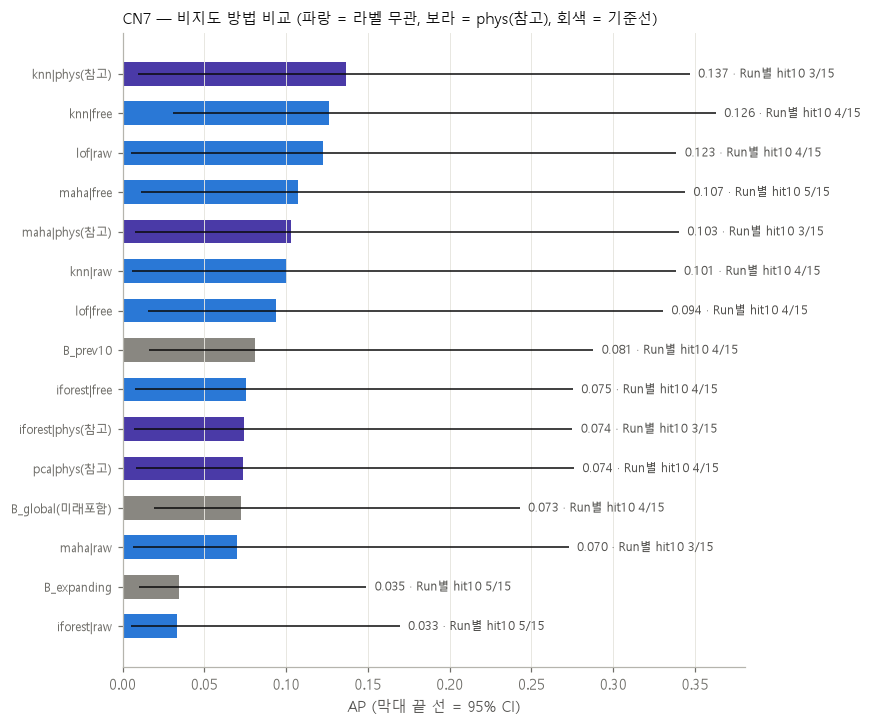

===== RG3 (전체 Run) =====


,product,method,n_def,AP,AP_lo,AP_hi,AP/base,hit@10%,전체 상위5%,전체 상위10%,AP_가스,hit10_가스,AP_미성형,hit10_미성형
18,rg3,iforest|raw,32,0.109,0.058,0.223,2.133,3/32,7/32,8/32,0.099,2/22,0.032,1/10
19,rg3,B_expanding,32,0.102,0.059,0.199,1.992,4/32,5/32,8/32,0.090,4/22,0.030,0/10
20,rg3,B_global(미래포함),32,0.097,0.052,0.202,1.908,4/32,6/32,7/32,0.080,3/22,0.036,1/10
21,rg3,B_prev10,32,0.096,0.063,0.188,1.882,4/32,3/32,8/32,0.081,3/22,0.031,1/10
22,rg3,knn|raw,32,0.090,0.053,0.175,1.755,5/32,5/32,8/32,0.073,3/22,0.030,2/10
23,rg3,maha|raw,32,0.079,0.049,0.158,1.545,4/32,4/32,6/32,0.073,4/22,0.020,0/10
24,rg3,lof|raw,32,0.076,0.052,0.139,1.497,4/32,4/32,6/32,0.059,3/22,0.027,1/10
25,rg3,iforest|free,32,0.074,0.047,0.155,1.448,3/32,3/32,4/32,0.069,2/22,0.019,1/10
26,rg3,lof|free,32,0.066,0.053,0.106,1.301,2/32,1/32,4/32,0.049,2/22,0.025,0/10
27,rg3,pca|free,32,0.066,0.051,0.100,1.296,6/32,2/32,4/32,0.050,5/22,0.023,1/10


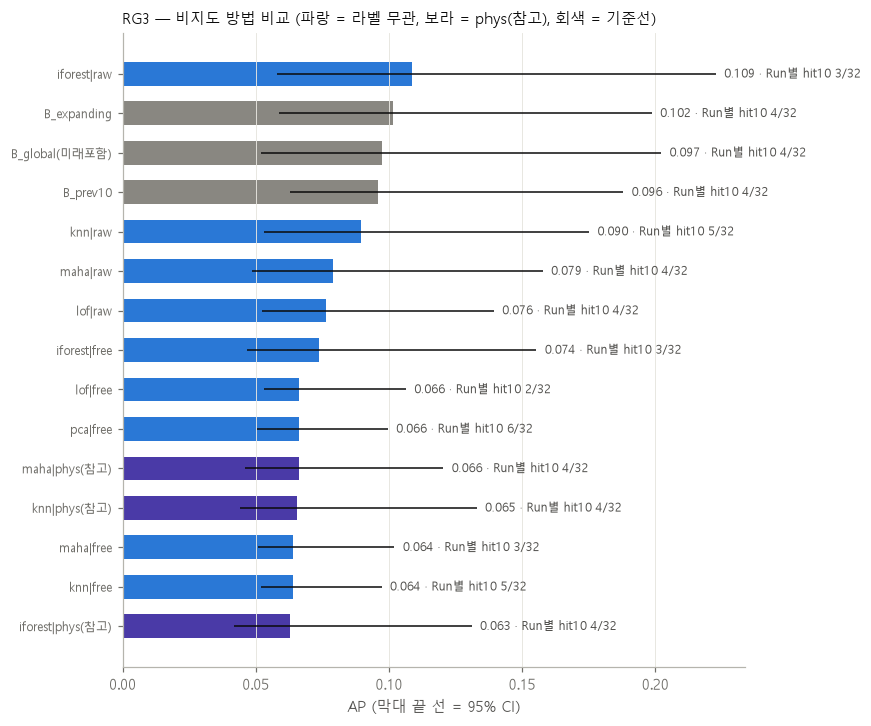

In [3]:
SUM = evaluate_v2(OOF)
SUM = SUM.merge(global_recall(OOF), on=['product', 'method'])
SUM.to_csv(f'{OUT}/summary_allruns.csv', index=False, encoding='utf-8-sig')
cols = ['product', 'method', 'n_def', 'AP', 'AP_lo', 'AP_hi', 'AP/base', 'hit@10%', '전체 상위5%', '전체 상위10%',
        'AP_가스', 'hit10_가스', 'AP_미성형', 'hit10_미성형']
for p in PRODUCTS:
    print(f'===== {p.upper()} (전체 Run) ====='); display(SUM[SUM['product'] == p][cols].round(3))
    plot_rank_compare(SUM, p, save=f'{OUT}/rank_{p}.png')

## 3. 순위 지표 — ② 2차 공식 데이터만 (팀원 기준과 같은 틀)
B_global·B_expanding이 여기선 높고 ①에선 떨어지면 → Run 수준 차이(R1 vs R2)를 잡은 것

In [4]:
O2 = OOF[OOF['split'] == '2차']
S2 = evaluate_v2(O2).merge(global_recall(O2), on=['product', 'method'])
S2.to_csv(f'{OUT}/summary_2cha.csv', index=False, encoding='utf-8-sig')
for p in PRODUCTS:
    print(f'===== {p.upper()} (2차만) =====')
    display(S2[S2['product'] == p][['product', 'method', 'n_def', 'base', 'AP', 'AP/base', '전체 상위5%', '전체 상위10%', 'hit@10%']].round(3))

===== CN7 (2차만) =====


,product,method,n_def,base,AP,AP/base,전체 상위5%,전체 상위10%,hit@10%
0,cn7,knn|phys(참고),14,0.023,0.243,10.500,3/14,3/14,3/14
1,cn7,knn|free,14,0.023,0.220,9.542,4/14,6/14,4/14
2,cn7,lof|raw,14,0.023,0.213,9.209,3/14,3/14,4/14
3,cn7,B_global(미래포함),14,0.023,0.184,7.975,5/14,10/14,4/14
4,cn7,maha|free,14,0.023,0.175,7.584,4/14,5/14,5/14
5,cn7,maha|phys(참고),14,0.023,0.160,6.944,3/14,3/14,3/14
6,cn7,knn|raw,14,0.023,0.157,6.801,3/14,3/14,4/14
7,cn7,lof|free,14,0.023,0.151,6.553,4/14,4/14,4/14
8,cn7,B_prev10,14,0.023,0.150,6.485,3/14,4/14,4/14
9,cn7,iforest|free,14,0.023,0.129,5.578,3/14,4/14,4/14


===== RG3 (2차만) =====


,product,method,n_def,base,AP,AP/base,전체 상위5%,전체 상위10%,hit@10%
18,rg3,B_prev10,25,0.042,0.060,1.412,2/25,5/25,3/25
19,rg3,lof|free,25,0.042,0.055,1.311,1/25,3/25,2/25
20,rg3,pca|free,25,0.042,0.055,1.306,0/25,4/25,4/25
21,rg3,lof|phys(참고),25,0.042,0.053,1.247,1/25,3/25,3/25
22,rg3,lof|raw,25,0.042,0.051,1.203,1/25,3/25,4/25
23,rg3,knn|free,25,0.042,0.049,1.149,1/25,2/25,4/25
24,rg3,knn|phys(참고),25,0.042,0.049,1.147,3/25,3/25,3/25
25,rg3,B_expanding,25,0.042,0.048,1.141,1/25,3/25,4/25
26,rg3,maha|free,25,0.042,0.048,1.128,1/25,2/25,2/25
27,rg3,pca|raw,25,0.042,0.046,1.084,2/25,2/25,3/25


## 4. 정상/불량 판정 — unlabeled 분위수 임계값 (라벨 미사용)

In [5]:
TT = threshold_table(OOF)
TT.to_csv(f'{OUT}/threshold_table.csv', index=False, encoding='utf-8-sig')
MAIN = ['knn|free', 'iforest|free', 'maha|free', 'knn|raw', 'iforest|raw', 'knn|phys(참고)', 'B_prev10', 'B_expanding']
display(TT[TT['method'].isin(MAIN)].round(3))
print('방법별 F1 최고 q (⚠ 라벨로 고른 사후 최적 — 참고용)')
display(best_per_method(TT)[['product', 'method', 'q', 'TP', 'FP', 'FN', 'Precision', 'Recall', 'F1',
                             '가스 탐지', '미성형계열 탐지']].round(3).groupby('product').head(8))

,product,method,q,가정 불량률(unlabeled),판정 불량(labeled),labeled 판정 비율,TP,FP,FN,Precision,Recall,F1,가스 탐지,미성형계열 탐지
0,cn7,iforest|raw,0.950,5%,272,0.138,3,269,12,0.011,0.200,0.021,0,3
1,cn7,iforest|raw,0.980,2%,3,0.002,0,3,15,0.000,0.000,0.000,0,0
2,cn7,iforest|raw,0.990,1%,2,0.001,0,2,15,0.000,0.000,0.000,0,0
3,cn7,iforest|raw,0.995,0.5%,1,0.001,0,1,15,0.000,0.000,0.000,0,0
4,cn7,iforest|raw,0.999,0.1%,0,0.000,0,0,15,0.000,0.000,0.000,0,0
10,cn7,knn|raw,0.950,5%,1357,0.687,5,1352,10,0.004,0.333,0.007,1,4
11,cn7,knn|raw,0.980,2%,856,0.434,5,851,10,0.006,0.333,0.011,1,4
12,cn7,knn|raw,0.990,1%,551,0.279,4,547,11,0.007,0.267,0.014,1,3
13,cn7,knn|raw,0.995,0.5%,237,0.120,3,234,12,0.013,0.200,0.024,0,3
14,cn7,knn|raw,0.999,0.1%,16,0.008,3,13,12,0.188,0.200,0.194,0,3


방법별 F1 최고 q (⚠ 라벨로 고른 사후 최적 — 참고용)


,product,method,q,TP,FP,FN,Precision,Recall,F1,가스 탐지,미성형계열 탐지
64,cn7,knn|phys(참고),0.999,3,2,12,0.600,0.200,0.300,0,3
39,cn7,knn|free,0.999,3,3,12,0.500,0.200,0.286,0,3
19,cn7,lof|raw,0.999,3,3,12,0.500,0.200,0.286,0,3
6,cn7,maha|raw,0.980,3,4,12,0.429,0.200,0.273,0,3
73,cn7,pca|phys(참고),0.995,3,4,12,0.429,0.200,0.273,0,3
29,cn7,iforest|free,0.999,3,5,12,0.375,0.200,0.261,0,3
58,cn7,maha|phys(참고),0.995,3,6,12,0.333,0.200,0.250,0,3
44,cn7,lof|free,0.999,3,7,12,0.300,0.200,0.240,0,3
90,rg3,iforest|raw,0.950,6,25,26,0.194,0.188,0.190,4,2
102,rg3,knn|raw,0.990,5,20,27,0.200,0.156,0.175,4,1


## 해석 가이드
- **labeled 판정 비율**이 (1−q)와 비슷하면 unlabeled→labeled 기준이 잘 맞는 것. 훨씬 크면 labeled 기간이 reference와 다름(드리프트)
- 순수 비지도(`raw`, `free`) 중 최고를 **비지도 대표**로, 13번 `E2_phys`·물리 규칙과 비교
- `raw`(수준값)가 ①에서 높으면 Run 수준 차이를 잡고 있을 가능성 → Run별 hit@10%가 같이 높은지 확인
- 팀원 결과와 비교는 ② 표의 B_prev10 / B_expanding / B_global이 팀원 수치(0.122 / 0.212 / 0.221)와 비슷한지로 확인
  (팀원 점수 정의가 다르면 수치는 다를 수 있음 — 변수·합치는 방식 확인 필요)